In [2]:
# M1 - Step 1
# Load the analytical dataset for statistical/modeling analysis

import pandas as pd
import numpy as np

file_path = r"C:\Users\vicky\OneDrive\Desktop\PROJECTS\Healthcare_Cost_Optimization_Analytics\data\Analytical_Dataset\healthcare_analytical_dataset.csv"

master = pd.read_csv(file_path)

print("Dataset Shape:", master.shape)
print("\nColumns:")
print(master.columns.tolist())

Dataset Shape: (61459, 58)

Columns:
['Id', 'START', 'STOP', 'PATIENT', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION', 'BIRTHDATE', 'PATIENT_GENDER', 'RACE', 'ETHNICITY', 'MARITAL', 'AGE_AT_ENCOUNTER', 'condition_count', 'procedure_count', 'procedure_cost', 'medication_count', 'medication_cost', 'immunization_count', 'immunization_cost', 'observation_count', 'allergy_count', 'careplan_count', 'device_count', 'imaging_study_count', 'supply_count', 'supply_quantity', 'PROVIDER_GENDER', 'PROVIDER_ORGANIZATION', 'GENDER', 'PROVIDER_SPECIALITY', 'PROVIDER_UTILIZATION', 'ORGANIZATION_NAME', 'ORGANIZATION_CITY', 'ORGANIZATION_STATE', 'ORGANIZATION_UTILIZATION', 'PAYER_NAME', 'PAYER_AMOUNT_COVERED', 'PAYER_AMOUNT_UNCOVERED', 'PAYER_QOLS_AVG', 'PAYER_MEMBER_MONTHS', 'claim_count', 'billed_claim_count', 'closed_claim_count', 'transaction_charge_amount', 'transaction_payment_amount', 'tr

In [3]:
# M1 - Step 2
# Identify target variable and candidate predictor groups

target = "TOTAL_CLAIM_COST"

candidate_predictors = {
    "Encounter / Patient": [
        "ENCOUNTERCLASS",
        "AGE_AT_ENCOUNTER",
        "PATIENT_GENDER",
        "RACE",
        "ETHNICITY",
        "MARITAL"
    ],

    "Clinical Utilization": [
        "condition_count",
        "procedure_count",
        "medication_count",
        "immunization_count",
        "observation_count",
        "allergy_count",
        "careplan_count",
        "device_count",
        "imaging_study_count",
        "supply_count",
        "supply_quantity"
    ],

    "Clinical Cost": [
        "procedure_cost",
        "medication_cost",
        "immunization_cost"
    ],

    "Provider / Organization": [
        "PROVIDER_UTILIZATION",
        "PROVIDER_SPECIALITY",
        "ORGANIZATION_UTILIZATION",
        "ORGANIZATION_STATE"
    ],

    "Payer": [
        "PAYER_NAME",
        "PAYER_COVERAGE",
        "PAYER_AMOUNT_COVERED",
        "PAYER_AMOUNT_UNCOVERED",
        "PAYER_QOLS_AVG",
        "PAYER_MEMBER_MONTHS"
    ],

    "Claims / Transactions": [
        "claim_count",
        "billed_claim_count",
        "closed_claim_count",
        "transaction_charge_amount",
        "transaction_payment_amount",
        "transaction_outstanding_amount",
        "transaction_count"
    ]
}

print("Target Variable:")
print(target)

print("\nCandidate Predictor Groups:")
for group, columns in candidate_predictors.items():
    print(f"\n{group}:")
    print(columns)
    4

Target Variable:
TOTAL_CLAIM_COST

Candidate Predictor Groups:

Encounter / Patient:
['ENCOUNTERCLASS', 'AGE_AT_ENCOUNTER', 'PATIENT_GENDER', 'RACE', 'ETHNICITY', 'MARITAL']

Clinical Utilization:
['condition_count', 'procedure_count', 'medication_count', 'immunization_count', 'observation_count', 'allergy_count', 'careplan_count', 'device_count', 'imaging_study_count', 'supply_count', 'supply_quantity']

Clinical Cost:
['procedure_cost', 'medication_cost', 'immunization_cost']

Provider / Organization:
['PROVIDER_UTILIZATION', 'PROVIDER_SPECIALITY', 'ORGANIZATION_UTILIZATION', 'ORGANIZATION_STATE']

Payer:
['PAYER_NAME', 'PAYER_COVERAGE', 'PAYER_AMOUNT_COVERED', 'PAYER_AMOUNT_UNCOVERED', 'PAYER_QOLS_AVG', 'PAYER_MEMBER_MONTHS']

Claims / Transactions:
['claim_count', 'billed_claim_count', 'closed_claim_count', 'transaction_charge_amount', 'transaction_payment_amount', 'transaction_outstanding_amount', 'transaction_count']


In [4]:
# M1 - Step 4
# Check selected modeling variables for missing values and data types

model_features = [
    "ENCOUNTERCLASS",
    "AGE_AT_ENCOUNTER",
    "PATIENT_GENDER",
    "RACE",
    "ETHNICITY",
    "MARITAL",
    "condition_count",
    "procedure_count",
    "medication_count",
    "immunization_count",
    "observation_count",
    "allergy_count",
    "careplan_count",
    "device_count",
    "imaging_study_count",
    "supply_count",
    "supply_quantity",
    "PROVIDER_UTILIZATION",
    "ORGANIZATION_UTILIZATION",
    "PAYER_NAME",
    "PAYER_QOLS_AVG",
    "PAYER_MEMBER_MONTHS"
]

model_check = master[model_features + [target]].copy()

print("Modeling Dataset Shape:", model_check.shape)

print("\nMissing Values:")
print(model_check.isna().sum())

print("\nData Types:")
print(model_check.dtypes)

Modeling Dataset Shape: (61459, 23)

Missing Values:
ENCOUNTERCLASS                  0
AGE_AT_ENCOUNTER                0
PATIENT_GENDER                  0
RACE                            0
ETHNICITY                       0
MARITAL                     10613
condition_count                 0
procedure_count                 0
medication_count                0
immunization_count              0
observation_count               0
allergy_count                   0
careplan_count                  0
device_count                    0
imaging_study_count             0
supply_count                    0
supply_quantity                 0
PROVIDER_UTILIZATION            0
ORGANIZATION_UTILIZATION        0
PAYER_NAME                      0
PAYER_QOLS_AVG                  0
PAYER_MEMBER_MONTHS             0
TOTAL_CLAIM_COST                0
dtype: int64

Data Types:
ENCOUNTERCLASS                  str
AGE_AT_ENCOUNTER            float64
PATIENT_GENDER                  str
RACE                           

In [5]:
# M1 - Step 5
# Prepare the modeling dataset

model_data = model_check.copy()

# Treat missing marital status as a separate category
model_data["MARITAL"] = model_data["MARITAL"].fillna("Unknown")

# Confirm missing values are handled
print("Missing values after treatment:")
print(model_data.isna().sum().sum())

print("\nModeling Dataset Shape:")
print(model_data.shape)

print("\nMarital categories:")
print(model_data["MARITAL"].value_counts())

Missing values after treatment:
0

Modeling Dataset Shape:
(61459, 23)

Marital categories:
MARITAL
M          39757
S          11089
Unknown    10613
Name: count, dtype: int64


In [6]:
# M2 - Step 1
# Separate predictors and target, then create train/test sets

from sklearn.model_selection import train_test_split

X = model_data[model_features].copy()
y = model_data[target].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)



Training set:
X_train: (49167, 22)
y_train: (49167,)

Testing set:
X_test: (12292, 22)
y_test: (12292,)


In [7]:
# M2 - Step 2
# Identify numerical and categorical predictors

categorical_features = [
    "ENCOUNTERCLASS",
    "PATIENT_GENDER",
    "RACE",
    "ETHNICITY",
    "MARITAL",
    "PAYER_NAME"
]

numerical_features = [
    "AGE_AT_ENCOUNTER",
    "condition_count",
    "procedure_count",
    "medication_count",
    "immunization_count",
    "observation_count",
    "allergy_count",
    "careplan_count",
    "device_count",
    "imaging_study_count",
    "supply_count",
    "supply_quantity",
    "PROVIDER_UTILIZATION",
    "ORGANIZATION_UTILIZATION",
    "PAYER_QOLS_AVG",
    "PAYER_MEMBER_MONTHS"
]

print("Categorical Features:", len(categorical_features))
print(categorical_features)

print("\nNumerical Features:", len(numerical_features))
print(numerical_features)

print("\nTotal Predictors:", len(categorical_features) + len(numerical_features))

Categorical Features: 6
['ENCOUNTERCLASS', 'PATIENT_GENDER', 'RACE', 'ETHNICITY', 'MARITAL', 'PAYER_NAME']

Numerical Features: 16
['AGE_AT_ENCOUNTER', 'condition_count', 'procedure_count', 'medication_count', 'immunization_count', 'observation_count', 'allergy_count', 'careplan_count', 'device_count', 'imaging_study_count', 'supply_count', 'supply_quantity', 'PROVIDER_UTILIZATION', 'ORGANIZATION_UTILIZATION', 'PAYER_QOLS_AVG', 'PAYER_MEMBER_MONTHS']

Total Predictors: 22


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Preprocessing for categorical features
categorical_transformer = OneHotEncoder(
    handle_unknown="ignore"
)

# Preprocessing for numerical features
numerical_transformer = StandardScaler()

# Combine both preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", categorical_transformer, categorical_features),
        ("numerical", numerical_transformer, numerical_features)
    ]
)

print("Preprocessing pipeline created successfully.")
print("Categorical features:", len(categorical_features))
print("Numerical features:", len(numerical_features))
print("Total input features:", len(categorical_features) + len(numerical_features))

Preprocessing pipeline created successfully.
Categorical features: 6
Numerical features: 16
Total input features: 22


In [9]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Baseline: predict the mean training cost for every test record
baseline_prediction = np.full(
    shape=len(y_test),
    fill_value=y_train.mean()
)

baseline_mae = mean_absolute_error(y_test, baseline_prediction)
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_prediction))
baseline_r2 = r2_score(y_test, baseline_prediction)

print("Baseline Model Performance")
print("-" * 35)
print(f"Training Mean Cost: ${y_train.mean():,.2f}")
print(f"MAE: ${baseline_mae:,.2f}")
print(f"RMSE: ${baseline_rmse:,.2f}")
print(f"R²: {baseline_r2:.4f}")

Baseline Model Performance
-----------------------------------
Training Mean Cost: $4,163.28
MAE: $5,515.74
RMSE: $10,115.98
R²: -0.0000


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

# Create Linear Regression pipeline
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train the model
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [11]:
# Generate predictions on the test dataset
linear_predictions = linear_model.predict(X_test)

# Calculate evaluation metrics
linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Performance")
print("-" * 35)
print(f"MAE: ${linear_mae:,.2f}")
print(f"RMSE: ${linear_rmse:,.2f}")
print(f"R²: {linear_r2:.4f}")

print("\nComparison with Baseline")
print("-" * 35)
print(f"Baseline MAE:  ${baseline_mae:,.2f}")
print(f"Linear MAE:    ${linear_mae:,.2f}")
print(f"Baseline RMSE: ${baseline_rmse:,.2f}")
print(f"Linear RMSE:   ${linear_rmse:,.2f}")
print(f"Baseline R²:   {baseline_r2:.4f}")
print(f"Linear R²:     {linear_r2:.4f}")

Linear Regression Performance
-----------------------------------
MAE: $4,390.25
RMSE: $8,475.29
R²: 0.2980

Comparison with Baseline
-----------------------------------
Baseline MAE:  $5,515.74
Linear MAE:    $4,390.25
Baseline RMSE: $10,115.98
Linear RMSE:   $8,475.29
Baseline R²:   -0.0000
Linear R²:     0.2980


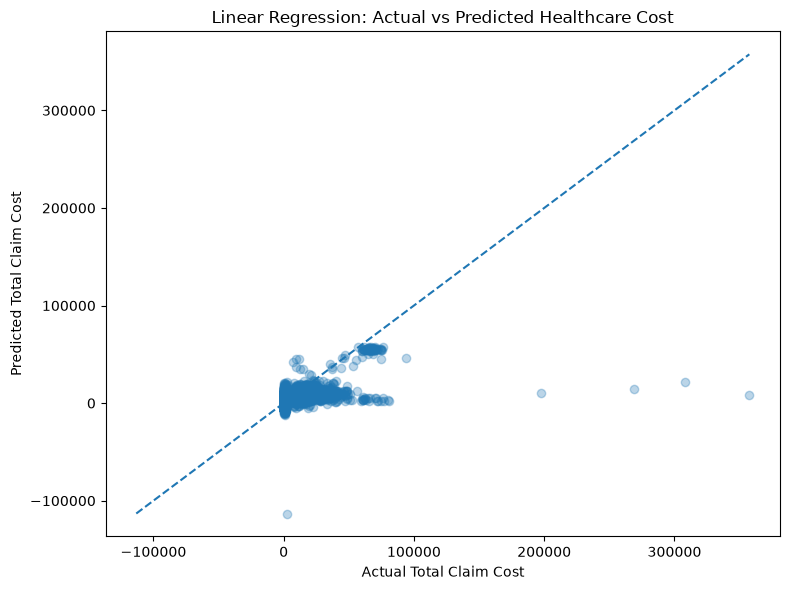

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    linear_predictions,
    alpha=0.3
)

# Perfect prediction reference line
min_value = min(y_test.min(), linear_predictions.min())
max_value = max(y_test.max(), linear_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Total Claim Cost")
plt.ylabel("Predicted Total Claim Cost")
plt.title("Linear Regression: Actual vs Predicted Healthcare Cost")

plt.tight_layout()
plt.show()

In [13]:
from sklearn.ensemble import RandomForestRegressor

# Create Random Forest pipeline
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Train the model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [14]:
# Generate predictions on the test dataset
rf_predictions = random_forest_model.predict(X_test)

# Calculate evaluation metrics
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Performance")
print("-" * 35)
print(f"MAE: ${rf_mae:,.2f}")
print(f"RMSE: ${rf_rmse:,.2f}")
print(f"R²: {rf_r2:.4f}")

print("\nComparison of Models")
print("-" * 50)
print(f"{'Metric':<10} {'Baseline':>15} {'Linear Regression':>20} {'Random Forest':>18}")
print("-" * 50)
print(f"{'MAE':<10} ${baseline_mae:>14,.2f} ${linear_mae:>19,.2f} ${rf_mae:>17,.2f}")
print(f"{'RMSE':<10} ${baseline_rmse:>14,.2f} ${linear_rmse:>19,.2f} ${rf_rmse:>17,.2f}")
print(f"{'R²':<10} {baseline_r2:>15.4f} {linear_r2:>20.4f} {rf_r2:>18.4f}")

Random Forest Performance
-----------------------------------
MAE: $1,761.36
RMSE: $7,638.83
R²: 0.4298

Comparison of Models
--------------------------------------------------
Metric            Baseline    Linear Regression      Random Forest
--------------------------------------------------
MAE        $      5,515.74 $           4,390.25 $         1,761.36
RMSE       $     10,115.98 $           8,475.29 $         7,638.83
R²                 -0.0000               0.2980             0.4298


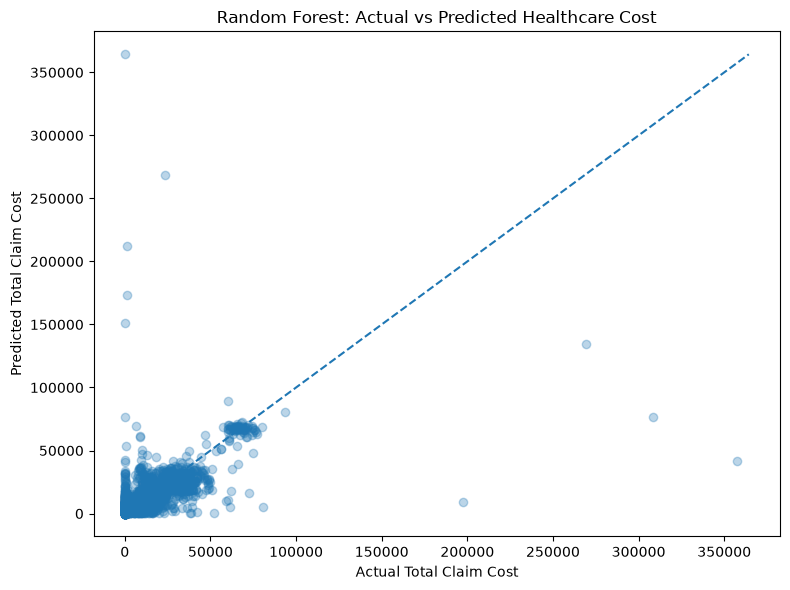

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.3
)

# Perfect prediction reference line
min_value = min(y_test.min(), rf_predictions.min())
max_value = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Total Claim Cost")
plt.ylabel("Predicted Total Claim Cost")
plt.title("Random Forest: Actual vs Predicted Healthcare Cost")

plt.tight_layout()
plt.show()

In [16]:
# Get the fitted preprocessing and Random Forest model
fitted_preprocessor = random_forest_model.named_steps["preprocessor"]
fitted_rf = random_forest_model.named_steps["model"]

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get Random Forest feature importance
importance_values = fitted_rf.feature_importances_

# Create feature importance dataframe
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 Model Features")
print("-" * 50)
print(feature_importance.head(20).to_string(index=False))

Top 20 Model Features
--------------------------------------------------
                                 Feature  Importance
              numerical__procedure_count    0.253085
             numerical__AGE_AT_ENCOUNTER    0.119987
             numerical__medication_count    0.097230
            numerical__observation_count    0.076880
categorical__PAYER_NAME_UnitedHealthcare    0.044752
     numerical__ORGANIZATION_UTILIZATION    0.042888
         numerical__PROVIDER_UTILIZATION    0.038300
              numerical__condition_count    0.036567
                  categorical__MARITAL_S    0.033937
               numerical__careplan_count    0.021767
          numerical__PAYER_MEMBER_MONTHS    0.019485
  categorical__ENCOUNTERCLASS_ambulatory    0.019344
  categorical__ENCOUNTERCLASS_urgentcare    0.018439
                 numerical__device_count    0.018247
               numerical__PAYER_QOLS_AVG    0.017319
   categorical__ENCOUNTERCLASS_emergency    0.014380
           categorical__PA

In [17]:
# Original categorical and numerical features
all_original_features = categorical_features + numerical_features

aggregated_importance = []

for original_feature in all_original_features:
    total_importance = 0
    
    # Numerical feature
    numerical_name = f"numerical__{original_feature}"
    
    if numerical_name in feature_importance["Feature"].values:
        total_importance += feature_importance.loc[
            feature_importance["Feature"] == numerical_name,
            "Importance"
        ].iloc[0]
    
    # One-hot encoded categorical features
    categorical_prefix = f"categorical__{original_feature}_"
    
    categorical_importance = feature_importance[
        feature_importance["Feature"].str.startswith(categorical_prefix)
    ]["Importance"].sum()
    
    total_importance += categorical_importance
    
    aggregated_importance.append({
        "Original_Feature": original_feature,
        "Importance": total_importance
    })

# Create aggregated dataframe
aggregated_importance = pd.DataFrame(aggregated_importance)

# Sort by importance
aggregated_importance = aggregated_importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

# Display all original features
print("Aggregated Feature Importance")
print("-" * 50)
print(aggregated_importance.to_string(index=False))

Aggregated Feature Importance
--------------------------------------------------
        Original_Feature  Importance
         procedure_count    0.253085
        AGE_AT_ENCOUNTER    0.119987
        medication_count    0.097230
              PAYER_NAME    0.083696
       observation_count    0.076880
          ENCOUNTERCLASS    0.067040
ORGANIZATION_UTILIZATION    0.042888
                 MARITAL    0.042817
    PROVIDER_UTILIZATION    0.038300
         condition_count    0.036567
                    RACE    0.026044
          PATIENT_GENDER    0.023602
          careplan_count    0.021767
     PAYER_MEMBER_MONTHS    0.019485
            device_count    0.018247
          PAYER_QOLS_AVG    0.017319
         supply_quantity    0.003987
            supply_count    0.003345
     imaging_study_count    0.003124
               ETHNICITY    0.002156
      immunization_count    0.002116
           allergy_count    0.000318


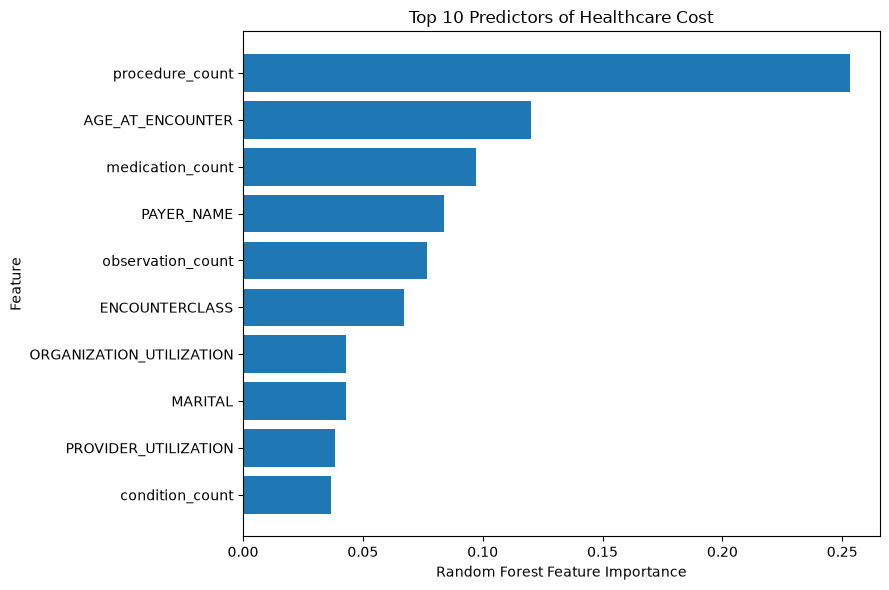

In [18]:
import matplotlib.pyplot as plt

# Select top 10 original features
top_10_importance = aggregated_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_10_importance["Original_Feature"],
    top_10_importance["Importance"]
)

plt.xlabel("Random Forest Feature Importance")
plt.ylabel("Feature")
plt.title("Top 10 Predictors of Healthcare Cost")

plt.tight_layout()
plt.show()

In [19]:
# Create an error-analysis dataframe
error_analysis = pd.DataFrame({
    "Actual_Cost": y_test.values,
    "Predicted_Cost": rf_predictions
})

# Calculate prediction error
error_analysis["Error"] = (
    error_analysis["Actual_Cost"] - error_analysis["Predicted_Cost"]
)

# Absolute error
error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

# Percentage error where actual cost is greater than zero
error_analysis["Absolute_Percentage_Error"] = (
    error_analysis["Absolute_Error"] /
    error_analysis["Actual_Cost"].replace(0, np.nan)
) * 100

print("Error Analysis Summary")
print("-" * 40)

print(f"Mean Absolute Error: ${error_analysis['Absolute_Error'].mean():,.2f}")
print(f"Median Absolute Error: ${error_analysis['Absolute_Error'].median():,.2f}")
print(f"Maximum Absolute Error: ${error_analysis['Absolute_Error'].max():,.2f}")

print("\nLargest Prediction Errors")
print("-" * 40)

print(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .to_string(index=False)
)

Error Analysis Summary
----------------------------------------
Mean Absolute Error: $1,761.36
Median Absolute Error: $257.76
Maximum Absolute Error: $364,225.08

Largest Prediction Errors
----------------------------------------
 Actual_Cost  Predicted_Cost         Error  Absolute_Error  Absolute_Percentage_Error
      129.16    364354.23835 -364225.07835    364225.07835              281995.260413
   357497.70     41988.86115  315508.83885    315508.83885                  88.254788
    23619.32    268808.59005 -245189.27005    245189.27005                1038.087761
   308315.25     76386.19095  231929.05905    231929.05905                  75.224647
     1110.79    211947.18815 -210836.39815    210836.39815               18980.761274
   197758.27      9521.22830  188237.04170    188237.04170                  95.185421
     1110.79    172989.98415 -171879.19415    171879.19415               15473.599344
      129.16    151285.59870 -151156.43870    151156.43870              117030.379

In [20]:
# Create an error-analysis dataframe
error_analysis = pd.DataFrame({
    "Actual_Cost": y_test.values,
    "Predicted_Cost": rf_predictions
})

# Calculate prediction error
error_analysis["Error"] = (
    error_analysis["Actual_Cost"] - error_analysis["Predicted_Cost"]
)

# Absolute error
error_analysis["Absolute_Error"] = (
    error_analysis["Error"].abs()
)

# Percentage error where actual cost is greater than zero
error_analysis["Absolute_Percentage_Error"] = (
    error_analysis["Absolute_Error"] /
    error_analysis["Actual_Cost"].replace(0, np.nan)
) * 100

print("Error Analysis Summary")
print("-" * 40)

print(f"Mean Absolute Error: ${error_analysis['Absolute_Error'].mean():,.2f}")
print(f"Median Absolute Error: ${error_analysis['Absolute_Error'].median():,.2f}")
print(f"Maximum Absolute Error: ${error_analysis['Absolute_Error'].max():,.2f}")

print("\nLargest Prediction Errors")
print("-" * 40)

print(
    error_analysis
    .sort_values("Absolute_Error", ascending=False)
    .head(10)
    .to_string(index=False)
)

Error Analysis Summary
----------------------------------------
Mean Absolute Error: $1,761.36
Median Absolute Error: $257.76
Maximum Absolute Error: $364,225.08

Largest Prediction Errors
----------------------------------------
 Actual_Cost  Predicted_Cost         Error  Absolute_Error  Absolute_Percentage_Error
      129.16    364354.23835 -364225.07835    364225.07835              281995.260413
   357497.70     41988.86115  315508.83885    315508.83885                  88.254788
    23619.32    268808.59005 -245189.27005    245189.27005                1038.087761
   308315.25     76386.19095  231929.05905    231929.05905                  75.224647
     1110.79    211947.18815 -210836.39815    210836.39815               18980.761274
   197758.27      9521.22830  188237.04170    188237.04170                  95.185421
     1110.79    172989.98415 -171879.19415    171879.19415               15473.599344
      129.16    151285.59870 -151156.43870    151156.43870              117030.379

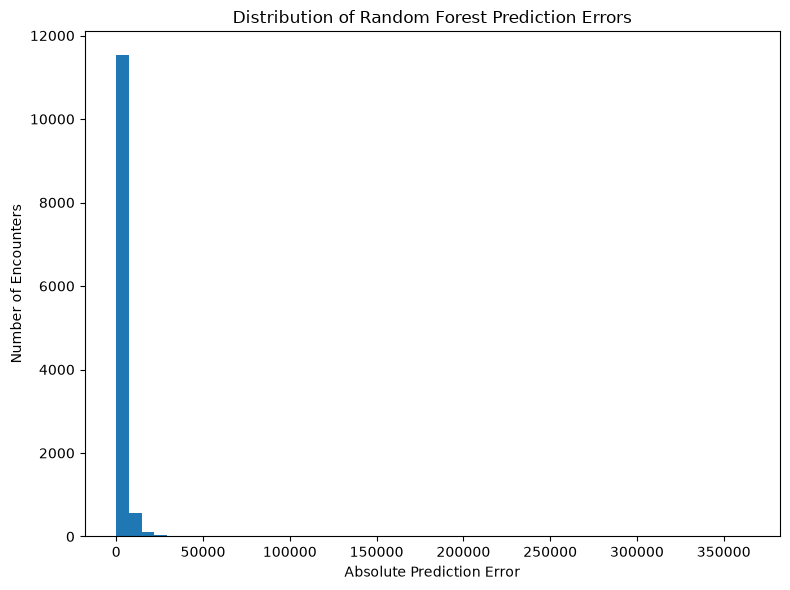

In [21]:
plt.figure(figsize=(8, 6))

plt.hist(
    error_analysis["Absolute_Error"],
    bins=50
)

plt.xlabel("Absolute Prediction Error")
plt.ylabel("Number of Encounters")
plt.title("Distribution of Random Forest Prediction Errors")

plt.tight_layout()
plt.show()

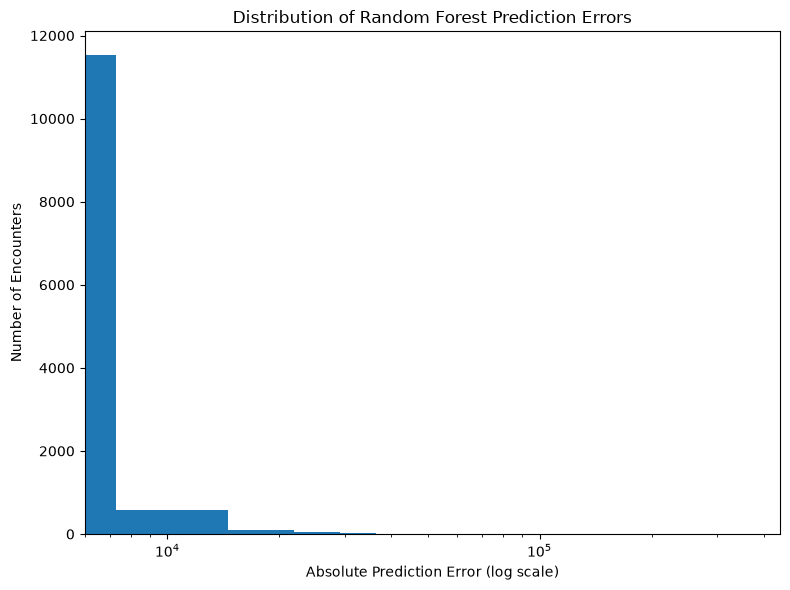

In [22]:
plt.figure(figsize=(8, 6))

plt.hist(
    error_analysis["Absolute_Error"],
    bins=50
)

plt.xscale("log")

plt.xlabel("Absolute Prediction Error (log scale)")
plt.ylabel("Number of Encounters")
plt.title("Distribution of Random Forest Prediction Errors")

plt.tight_layout()
plt.show()

In [23]:
from sklearn.compose import TransformedTargetRegressor

# Random Forest pipeline for log-transformed target
log_rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

# Transform target using log1p during training
log_rf_model = TransformedTargetRegressor(
    regressor=log_rf_pipeline,
    func=np.log1p,
    inverse_func=np.expm1
)

# Train the log-transformed Random Forest
log_rf_model.fit(X_train, y_train)

print("Log-Transformed Random Forest model trained successfully.")

Log-Transformed Random Forest model trained successfully.


In [24]:
# Generate predictions on the original dollar scale
log_rf_predictions = log_rf_model.predict(X_test)

# Calculate evaluation metrics
log_rf_mae = mean_absolute_error(y_test, log_rf_predictions)
log_rf_rmse = np.sqrt(mean_squared_error(y_test, log_rf_predictions))
log_rf_r2 = r2_score(y_test, log_rf_predictions)

print("Log-Transformed Random Forest Performance")
print("-" * 50)
print(f"MAE: ${log_rf_mae:,.2f}")
print(f"RMSE: ${log_rf_rmse:,.2f}")
print(f"R²: {log_rf_r2:.4f}")

print("\nComparison with Standard Random Forest")
print("-" * 50)
print(f"{'Metric':<10} {'Standard RF':>18} {'Log-Transformed RF':>22}")
print("-" * 50)
print(f"{'MAE':<10} ${rf_mae:>17,.2f} ${log_rf_mae:>21,.2f}")
print(f"{'RMSE':<10} ${rf_rmse:>17,.2f} ${log_rf_rmse:>21,.2f}")
print(f"{'R²':<10} {rf_r2:>18.4f} {log_rf_r2:>22.4f}")

Log-Transformed Random Forest Performance
--------------------------------------------------
MAE: $1,557.67
RMSE: $6,741.13
R²: 0.5559

Comparison with Standard Random Forest
--------------------------------------------------
Metric            Standard RF     Log-Transformed RF
--------------------------------------------------
MAE        $         1,761.36 $             1,557.67
RMSE       $         7,638.83 $             6,741.13
R²                     0.4298                 0.5559


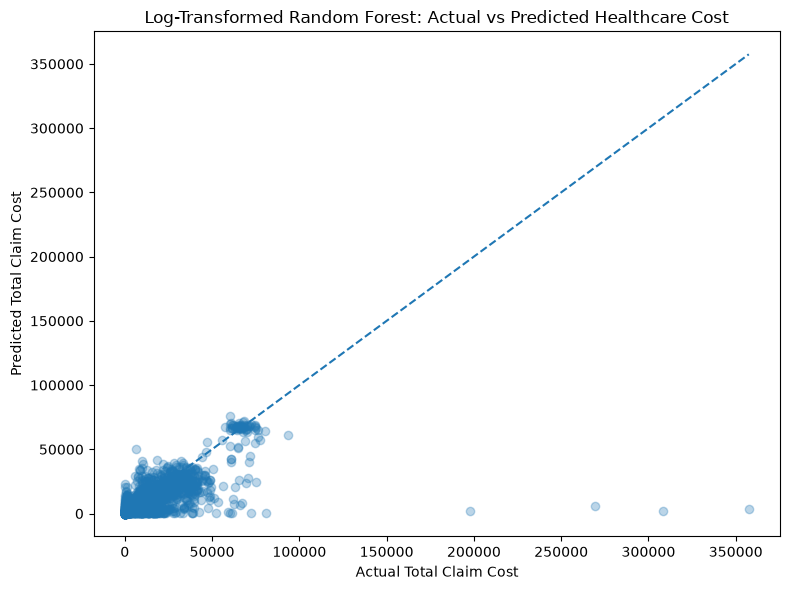

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    log_rf_predictions,
    alpha=0.3
)

# Perfect prediction reference line
min_value = min(y_test.min(), log_rf_predictions.min())
max_value = max(y_test.max(), log_rf_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Total Claim Cost")
plt.ylabel("Predicted Total Claim Cost")
plt.title("Log-Transformed Random Forest: Actual vs Predicted Healthcare Cost")

plt.tight_layout()
plt.show()

In [26]:
# Final model comparison

final_model_comparison = pd.DataFrame({
    "Model": [
        "Baseline",
        "Linear Regression",
        "Standard Random Forest",
        "Log-Transformed Random Forest"
    ],
    "MAE": [
        baseline_mae,
        linear_mae,
        rf_mae,
        log_rf_mae
    ],
    "RMSE": [
        baseline_rmse,
        linear_rmse,
        rf_rmse,
        log_rf_rmse
    ],
    "R2": [
        baseline_r2,
        linear_r2,
        rf_r2,
        log_rf_r2
    ]
})

print("Final Model Comparison")
print("=" * 75)

print(
    final_model_comparison.to_string(
        index=False,
        formatters={
            "MAE": "${:,.2f}".format,
            "RMSE": "${:,.2f}".format,
            "R2": "{:.4f}".format
        }
    )
)

Final Model Comparison
                        Model       MAE       RMSE      R2
                     Baseline $5,515.74 $10,115.98 -0.0000
            Linear Regression $4,390.25  $8,475.29  0.2980
       Standard Random Forest $1,761.36  $7,638.83  0.4298
Log-Transformed Random Forest $1,557.67  $6,741.13  0.5559


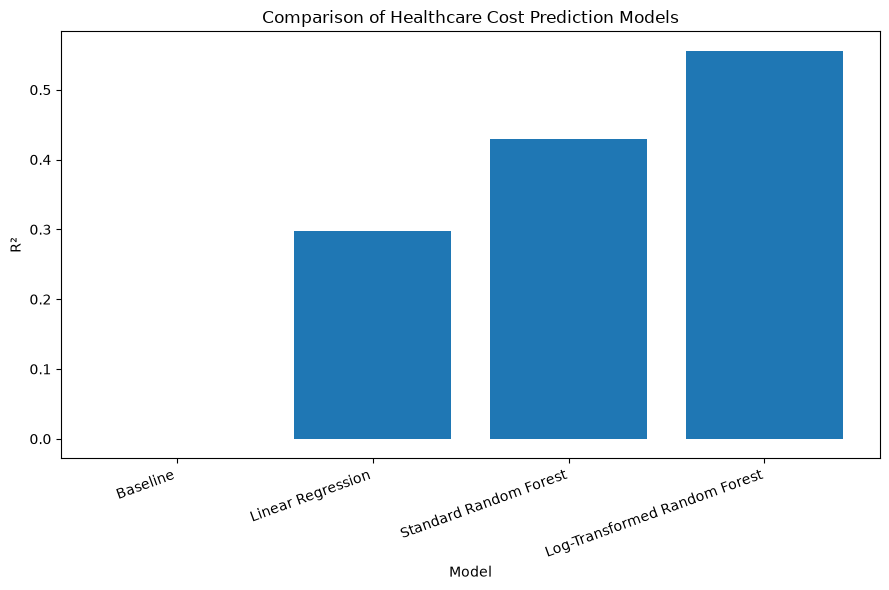

In [27]:
plt.figure(figsize=(9, 6))

plt.bar(
    final_model_comparison["Model"],
    final_model_comparison["R2"]
)

plt.xlabel("Model")
plt.ylabel("R²")
plt.title("Comparison of Healthcare Cost Prediction Models")

plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

In [28]:
print("=" * 70)
print("FINAL STATISTICAL MODELING SUMMARY")
print("=" * 70)

print("\nTarget Variable:")
print("TOTAL_CLAIM_COST — encounter-level healthcare cost")

print("\nBest Performing Model:")
print("Log-Transformed Random Forest")

print("\nBest Model Performance:")
print(f"MAE  : ${log_rf_mae:,.2f}")
print(f"RMSE : ${log_rf_rmse:,.2f}")
print(f"R²   : {log_rf_r2:.4f}")

print("\nTop Predictive Factors:")
for i, row in aggregated_importance.head(10).iterrows():
    print(
        f"{i + 1}. "
        f"{row['Original_Feature']} "
        f"({row['Importance']:.2%})"
    )

print("\nKey Modeling Limitation:")
print(
    "Extreme high-cost encounters remain difficult to predict accurately, "
    "despite the improved performance of the log-transformed model."
)

print("\nModeling Phase Status:")
print("COMPLETE")

FINAL STATISTICAL MODELING SUMMARY

Target Variable:
TOTAL_CLAIM_COST — encounter-level healthcare cost

Best Performing Model:
Log-Transformed Random Forest

Best Model Performance:
MAE  : $1,557.67
RMSE : $6,741.13
R²   : 0.5559

Top Predictive Factors:
1. procedure_count (25.31%)
2. AGE_AT_ENCOUNTER (12.00%)
3. medication_count (9.72%)
4. PAYER_NAME (8.37%)
5. observation_count (7.69%)
6. ENCOUNTERCLASS (6.70%)
7. ORGANIZATION_UTILIZATION (4.29%)
8. MARITAL (4.28%)
9. PROVIDER_UTILIZATION (3.83%)
10. condition_count (3.66%)

Key Modeling Limitation:
Extreme high-cost encounters remain difficult to predict accurately, despite the improved performance of the log-transformed model.

Modeling Phase Status:
COMPLETE
